# Grammar Scoring Engine for Spoken Audio

**Task:** predict a continuous MOS-style grammar score (0-5) from a 45-60 s speech recording.
Data: 769 labelled training clips, 216 test clips (`.wav`).

---
## 1. Report (summary)

### 1.1 Approach and why
Three options were considered:

| Option | Idea | Verdict |
|---|---|---|
| A. Audio embeddings | wav2vec2 / Whisper-encoder embeddings -> regressor | Mostly captures acoustics (accent, pitch, noise, speaker). Grammar is a *lexical-syntactic* property, so the signal is diluted, and with only 769 samples the regressor overfits speaker traits. |
| B. ASR -> text -> text model | Transcribe, then model the transcript | Matches the nature of the target. |
| **C. (chosen) Hybrid ASR-text pipeline** | B, but combining **explicit, interpretable grammar features** (parse structure, grammar-checker error rates, language-model fluency, disfluencies, ASR confidence) with **pretrained contextual text embeddings**, fused by a small stacked ensemble | Best fit: the handcrafted features map directly to the rubric (sentence completeness, syntactic complexity, error rate), the embeddings add coverage of patterns we did not hand-code, and the whole thing is trainable on <1k samples. |

### 1.2 Pipeline architecture
```
 .wav (16 kHz mono)
   |  preprocessing: resample, trim silence, peak-normalise
   v
 Whisper ASR (faster-whisper, greedy, no cross-segment conditioning)  --> transcript + ASR confidence stats
   |
   +--> Handcrafted grammar features
   |       spaCy: sentence length stats, fragments (no verb / no subject), dependency depth,
   |              subordination / coordination / passive / modal rates, POS ratios, tense variety
   |       LanguageTool: grammar-error rate per 100 words (casing/punctuation rules removed)
   |       GPT-2: token negative log-likelihood stats (fluency / grammaticality proxy)
   |       Disfluency: filler words, immediate word repetitions
   |       ASR: avg log-prob, compression ratio, no-speech prob
   |
   +--> RoBERTa mean-pooled embeddings (avg of last 4 layers)
   |
   v
 4 base regressors:  Ridge(emb)  SVR(emb)  Ridge(hand)  HistGradientBoosting(hand)
   |   -> inner 5-fold OOF predictions -> non-negative least-squares blending weights
   v
 weighted blend -> clip to [0, 5]  =>  grammar score
```

### 1.3 Preprocessing
Resample to 16 kHz mono, trim leading/trailing silence (top_db=30), peak-normalise, Whisper's built-in VAD filter.
Transcript text is lightly normalised only (whitespace). **Caveat:** ASR models tend to *silently correct* grammar
and drop disfluencies. To limit this, decoding is greedy (temperature 0), `condition_on_previous_text=False`
(no language-model "repair" from earlier context) and a short filler-word prompt is used so that "um/uh" are kept. ASR confidence
statistics are also kept as features because low confidence often accompanies broken or unusual speech.

### 1.4 Evaluation protocol
* **Holdout split**: 80/20 stratified split of the training set -> *train RMSE* and *validation RMSE*.
* **5-fold stratified CV** over the full training set -> out-of-fold (OOF) RMSE (most reliable generalisation estimate).
* **Final model** refit on all 769 samples -> *full-train RMSE* (**reported as required**) and predictions for the test set
  (test RMSE is computed if test labels are provided, otherwise predictions are saved to CSV).
* Metrics: RMSE (primary), MAE, Pearson, Spearman, Quadratic Weighted Kappa (on rounded scores).

*Final numbers are generated automatically in section 9 once the notebook has been run.*

## 2. Setup & configuration

In [ ]:

import os, re, json, warnings, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
import torch, librosa
from scipy.optimize import nnls
from scipy.stats import pearsonr, spearmanr

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.svm import SVR
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, cohen_kappa_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cuda


In [5]:
# ----------------------------- USER CONFIGURATION -----------------------------
# Edit these to match how the dataset is laid out.
DATA_ROOT       = Path("./data")
TRAIN_AUDIO_DIR = DATA_ROOT / "train"        # folder holding training .wav files
TEST_AUDIO_DIR  = DATA_ROOT / "test"         # folder holding test .wav files
TRAIN_CSV       = DATA_ROOT / "train.csv"    # table with file names + labels
TEST_CSV        = DATA_ROOT / "test.csv"     # test table (label column optional)
FILE_COL        = "filename"                 # column with the audio file name
LABEL_COL       = "label"                    # column with the grammar score

# ASR settings
WHISPER_SIZE      = "medium.en" if DEVICE == "cuda" else "small.en"   # use "base.en" for a quick CPU run
USE_FILLER_PROMPT = True      # nudges Whisper to keep "um/uh" (disfluencies)
USE_LANGUAGETOOL  = True      # needs Java; automatically skipped if unavailable

# Model names for text features
EMB_MODEL = "roberta-base"
LM_MODEL  = "gpt2"

WORK_DIR = Path("./artifacts"); WORK_DIR.mkdir(exist_ok=True)

In [6]:
def load_table(csv_path, audio_dir):
    """Read a label table and attach the absolute audio path of every row."""
    df = pd.read_csv(csv_path)
    names = df[FILE_COL].astype(str)
    names = names.where(names.str.lower().str.endswith(".wav"), names + ".wav")
    df["path"] = [str(Path(audio_dir) / n) for n in names]
    missing = [p for p in df["path"] if not os.path.exists(p)]
    assert not missing, f"{len(missing)} audio files not found, e.g. {missing[:3]}"
    return df

train_df = load_table(TRAIN_CSV, TRAIN_AUDIO_DIR)
test_df  = load_table(TEST_CSV, TEST_AUDIO_DIR)
TEST_HAS_LABELS = LABEL_COL in test_df.columns
print(f"train: {len(train_df)} | test: {len(test_df)} | test labels available: {TEST_HAS_LABELS}")
train_df.head()

train: 769 | test: 216 | test labels available: True


,filename,label,path
0,audio_192.wav,3.0,data/train/audio_192.wav
1,audio_436.wav,3.0,data/train/audio_436.wav
2,audio_447.wav,3.5,data/train/audio_447.wav
3,audio_126.wav,2.0,data/train/audio_126.wav
4,audio_61.wav,2.0,data/train/audio_61.wav


## 3. Exploratory look at the labels

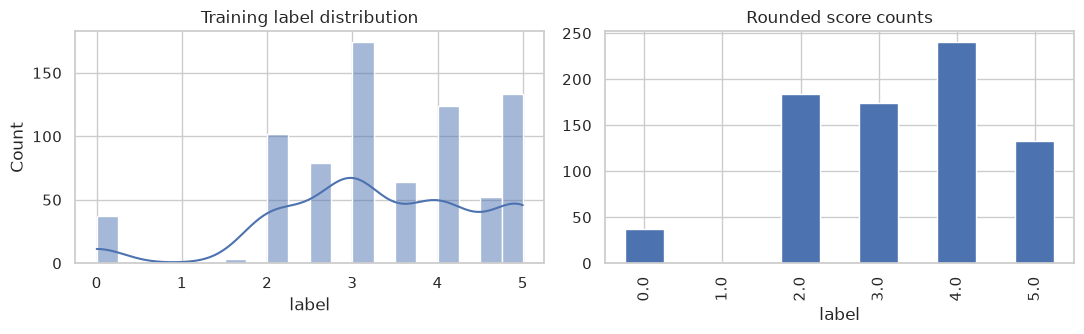

count    769.000000
mean       3.313394
std        1.239000
min        0.000000
25%        2.500000
50%        3.000000
75%        4.000000
max        5.000000
Name: label, dtype: float64


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(train_df[LABEL_COL], bins=20, kde=True, ax=ax[0]); ax[0].set_title("Training label distribution")
train_df[LABEL_COL].round().value_counts().sort_index().plot.bar(ax=ax[1]); ax[1].set_title("Rounded score counts")
plt.tight_layout(); plt.show()
print(train_df[LABEL_COL].describe())

## 4. Preprocessing and speech-to-text
Audio is resampled to 16 kHz mono, silence at both ends is trimmed and the peak is normalised.
Transcripts are cached in `artifacts/transcripts.json`, so the (slow) ASR step is only run once and the notebook can be resumed.

In [8]:
from faster_whisper import WhisperModel

SR = 16000
asr = WhisperModel(WHISPER_SIZE, device=DEVICE, compute_type="float16" if DEVICE == "cuda" else "int8")
FILLER_PROMPT = "Umm, let me think like, hmm... Okay, so, you know, uh, well."

def load_audio(path):
    """Load -> mono 16 kHz -> trim silence -> peak-normalise. Returns (waveform, raw duration in s)."""
    y, _ = librosa.load(path, sr=SR, mono=True)
    raw_dur = len(y) / SR
    y, _ = librosa.effects.trim(y, top_db=30)
    y = y / (np.max(np.abs(y)) + 1e-9) * 0.95
    return y.astype(np.float32), raw_dur

def transcribe(path):
    """Run Whisper on one file. Returns transcript text and ASR confidence statistics."""
    audio, dur = load_audio(path)
    segments, _ = asr.transcribe(
        audio, language="en", beam_size=5, temperature=0.0,
        condition_on_previous_text=False,       # prevents the model from "repairing" text using earlier context
        vad_filter=True,
        initial_prompt=FILLER_PROMPT if USE_FILLER_PROMPT else None,
    )
    segs = list(segments)
    text = re.sub(r"\s+", " ", " ".join(s.text.strip() for s in segs)).strip()
    stats = dict(
        duration=dur,
        asr_n_segments=len(segs),
        asr_avg_logprob=float(np.mean([s.avg_logprob for s in segs])) if segs else np.nan,
        asr_min_logprob=float(np.min([s.avg_logprob for s in segs])) if segs else np.nan,
        asr_no_speech=float(np.mean([s.no_speech_prob for s in segs])) if segs else np.nan,
        asr_compression=float(np.mean([s.compression_ratio for s in segs])) if segs else np.nan,
    )
    return text, stats

TRANSCRIPT_CACHE = WORK_DIR / "transcripts.json"
cache = json.load(open(TRANSCRIPT_CACHE)) if TRANSCRIPT_CACHE.exists() else {}

def transcribe_all(df):
    for p in tqdm(df["path"], desc="Transcribing"):
        if p not in cache:
            t, s = transcribe(p)
            cache[p] = {"text": t, **s}
            if len(cache) % 25 == 0:
                json.dump(cache, open(TRANSCRIPT_CACHE, "w"))
    json.dump(cache, open(TRANSCRIPT_CACHE, "w"))
    return pd.DataFrame([cache[p] for p in df["path"]], index=df.index)

train_df = pd.concat([train_df.drop(columns=["text"], errors="ignore"), transcribe_all(train_df)], axis=1)
test_df  = pd.concat([test_df.drop(columns=["text"], errors="ignore"),  transcribe_all(test_df)],  axis=1)
print("Empty transcripts:", (train_df.text.str.len() == 0).sum(), "train /", (test_df.text.str.len() == 0).sum(), "test")
for i in range(2):
    print(f"\n[label={train_df[LABEL_COL].iloc[i]:.2f}] {train_df.text.iloc[i][:400]}...")

Transcribing: 100%|██████████████████████████████████████████████████████████████████████████████████████████| 216/216 [15:11<00:00,  4.22s/it]

Empty transcripts: 0 train / 0 test

[label=3.00] Well, the playground is very, very beautiful and firm. There are, there are playthings like the merry-go-round, the swing. The students usually enjoy the swing. It has to be like, um, it's more like a game of chess because one fits in it and the other person will have to push. And the merry-go-round And most of the time you hear the sound of screaming children laughing in the game....

[label=3.00] The scene of a school playground. Our playground looks like a very big playground having more, more greenery trees. In which we students like to garden more trees to have fresh air and having a fresh oxygen. These, in the playground, these trees gives a very greenery view which will be very pleasant to our minds and will give We students like the activities of games like Coco, Volleyball and Runni...


## 5. Feature extraction
Each group is designed to reflect a part of the grammar rubric:

| Rubric element | Features |
|---|---|
| Incomplete sentences / fragments (score 1-2) | share of sentences with no verb or no subject, sentence-length stats |
| Basic grammar mistakes (score 2-3) | LanguageTool error rate per 100 words, GPT-2 negative log-likelihood stats |
| Complex structures (score 4-5) | dependency-tree depth, subordinate / relative / passive / coordination rates, tense variety, modal use |
| Self-correction / control | filler rate, immediate repetitions, ASR confidence |

In [9]:
import spacy, language_tool_python
from transformers import AutoTokenizer, AutoModel, AutoModelForCausalLM

try:
    nlp = spacy.load("en_core_web_sm")
except OSError:
    spacy.cli.download("en_core_web_sm"); nlp = spacy.load("en_core_web_sm")

lt = None
if USE_LANGUAGETOOL:
    try:
        lt = language_tool_python.LanguageTool("en-US")
    except Exception as e:                     # Java missing, no internet, ...
        print("LanguageTool unavailable, skipping those features:", repr(e)[:120])

lm_tok = AutoTokenizer.from_pretrained(LM_MODEL)
lm = AutoModelForCausalLM.from_pretrained(LM_MODEL).to(DEVICE).eval()
emb_tok = AutoTokenizer.from_pretrained(EMB_MODEL)
emb_model = AutoModel.from_pretrained(EMB_MODEL).to(DEVICE).eval()

Loading weights: 100%|████████████████████████████████████████████████████████████████████████████████████| 197/197 [00:00<00:00, 36179.96it/s]
[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [10]:
FILLERS = {"um", "umm", "uh", "uhh", "er", "erm", "ah", "hmm", "mm", "uhm"}
# LanguageTool categories that are about writing conventions rather than grammar; irrelevant for speech
LT_IGNORE = {"CASING", "PUNCTUATION", "TYPOGRAPHY", "STYLE", "WHITESPACE", "TYPOS"}
POS_LIST = ["NOUN", "VERB", "AUX", "ADJ", "ADV", "PRON", "DET", "ADP", "CCONJ", "SCONJ"]

def tree_depth(tok):
    d = 0
    while tok.head is not tok and d < 100:
        tok = tok.head; d += 1
    return d

def syntax_features(text):
    doc = nlp(text)
    words = [t for t in doc if not t.is_punct and not t.is_space]
    n = max(len(words), 1)
    sents = [s for s in doc.sents if len([t for t in s if not t.is_punct]) > 0]
    slen = np.array([len([t for t in s if not t.is_punct]) for s in sents]) if sents else np.array([0])
    no_verb = np.mean([not any(t.pos_ in ("VERB", "AUX") for t in s) for s in sents]) if sents else 1.0
    no_subj = np.mean([not any(t.dep_ in ("nsubj", "nsubjpass", "expl", "csubj") for t in s) for s in sents]) if sents else 1.0
    deps = [t.dep_ for t in words]
    per100 = lambda c: 100.0 * c / n
    tenses = {v for t in words for v in t.morph.get("Tense")}
    lower = [t.text.lower() for t in words]
    f = dict(
        n_words=len(words),
        ttr=len(set(lower)) / n,
        mean_word_len=np.mean([len(t.text) for t in words]) if words else 0,
        n_sents=len(sents), sent_len_mean=slen.mean(), sent_len_std=slen.std(), sent_len_max=slen.max(),
        frac_sent_no_verb=no_verb, frac_sent_no_subj=no_subj,
        depth_mean=np.mean([tree_depth(t) for t in words]) if words else 0,
        depth_max=max([tree_depth(t) for t in words]) if words else 0,
        subord_rate=per100(sum(d in ("mark", "advcl", "ccomp", "xcomp") for d in deps)),
        relcl_rate=per100(sum(d in ("relcl", "acl") for d in deps)),
        coord_rate=per100(sum(d in ("conj", "cc") for d in deps)),
        passive_rate=per100(sum(d in ("nsubjpass", "auxpass") for d in deps)),
        modal_rate=per100(sum(t.tag_ == "MD" for t in words)),
        n_tenses=len(tenses),
        filler_rate=per100(sum(w in FILLERS for w in lower)),
        repeat_rate=per100(sum(a == b for a, b in zip(lower, lower[1:]))),
    )
    for p in POS_LIST:
        f[f"pos_{p}"] = sum(t.pos_ == p for t in words) / n
    return f

def lt_features(text):
    if lt is None:
        return {}
    n = max(len(text.split()), 1)
    try:
        matches = lt.check(text)
    except Exception:
        return {"lt_err_rate": np.nan, "lt_grammar_rate": np.nan}
    cat = lambda m: str(getattr(m, "category", "") or getattr(m, "ruleIssueType", "")).upper()
    kept = [m for m in matches if cat(m) not in LT_IGNORE]
    return {"lt_err_rate": 100.0 * len(kept) / n,
            "lt_grammar_rate": 100.0 * sum(cat(m) == "GRAMMAR" for m in kept) / n}

@torch.no_grad()
def lm_features(text):
    """Token-level negative log-likelihood under GPT-2: ungrammatical text -> higher / spikier NLL."""
    ids = lm_tok(text, return_tensors="pt", truncation=True, max_length=1000).input_ids
    ids = torch.cat([torch.tensor([[lm_tok.bos_token_id]]), ids], dim=1).to(DEVICE)
    logits = lm(ids).logits[0, :-1]
    nll = torch.nn.functional.cross_entropy(logits, ids[0, 1:], reduction="none").cpu().numpy()
    return dict(lm_nll_mean=nll.mean(), lm_nll_std=nll.std(),
                lm_nll_p90=np.percentile(nll, 90), lm_frac_nll_gt8=(nll > 8).mean())

def handcrafted_features(text, asr_stats):
    text = text if text else "."
    return {**syntax_features(text), **lt_features(text), **lm_features(text), **asr_stats}

@torch.no_grad()
def embed_texts(texts, batch=16):
    """Mean-pooled (attention-masked) average of the last 4 hidden layers of RoBERTa."""
    out = []
    for i in range(0, len(texts), batch):
        enc = emb_tok(list(texts[i:i + batch]), return_tensors="pt", padding=True, truncation=True, max_length=512).to(DEVICE)
        hs = emb_model(**enc, output_hidden_states=True).hidden_states[-4:]
        h = torch.stack(hs).mean(0)
        m = enc.attention_mask.unsqueeze(-1)
        out.append(((h * m).sum(1) / m.sum(1)).cpu().numpy())
    return np.vstack(out)

ASR_COLS = ["duration", "asr_n_segments", "asr_avg_logprob", "asr_min_logprob", "asr_no_speech", "asr_compression"]

def build_features(df, name):
    hp, ep = WORK_DIR / f"{name}_hand.csv", WORK_DIR / f"{name}_emb.npy"
    if hp.exists() and ep.exists():                                    # reuse cache
        return pd.read_csv(hp), np.load(ep)
    rows = [handcrafted_features(r.text, {c: getattr(r, c) for c in ASR_COLS})
            for r in tqdm(df.itertuples(), total=len(df), desc=f"{name}: handcrafted")]
    H = pd.DataFrame(rows)
    E = embed_texts(df.text.fillna(".").tolist())
    H.to_csv(hp, index=False); np.save(ep, E)
    return H, E

H_train, E_train = build_features(train_df, "train")
H_test,  E_test  = build_features(test_df,  "test")
H_test = H_test.reindex(columns=H_train.columns)
y = train_df[LABEL_COL].values.astype(float)
print("handcrafted:", H_train.shape, "| embeddings:", E_train.shape)

test: handcrafted: 100%|█████████████████████████████████████████████████████████████████████████████████████| 216/216 [00:07<00:00, 28.09it/s]


handcrafted: (769, 41) | embeddings: (769, 768)


### 5.1 Which handcrafted features relate to the grammar score?

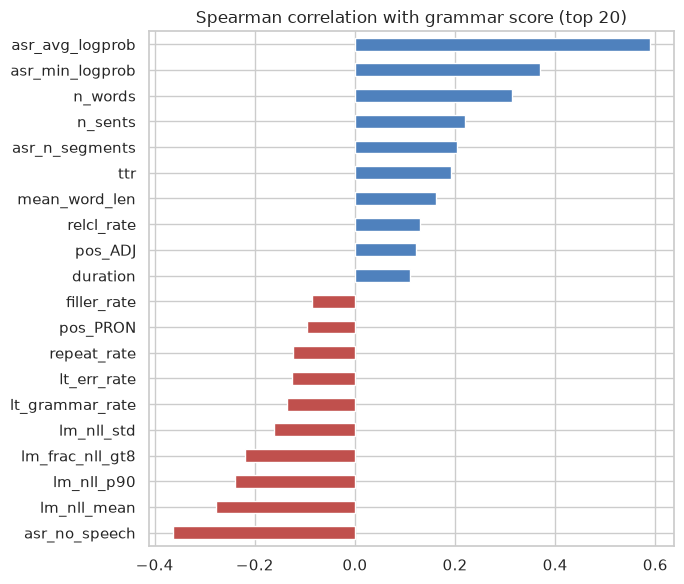

In [11]:
corr = H_train.assign(label=y).corr(method="spearman")["label"].drop("label").dropna().sort_values()
top = pd.concat([corr.head(10), corr.tail(10)])
plt.figure(figsize=(7, 6))
top.plot.barh(color=["#c0504d" if v < 0 else "#4f81bd" for v in top])
plt.title("Spearman correlation with grammar score (top 20)"); plt.tight_layout(); plt.show()

## 6. Model: stacked ensemble
Four small, regularised regressors (suitable for ~800 samples). Blend weights are learned with **non-negative least squares on inner 5-fold out-of-fold predictions**
(computed *only* on the training portion, so validation / test data never influences the weights).

In [12]:
def make_models():
    """name -> (estimator, feature-block it consumes)."""
    return {
        "ridge_emb": (Pipeline([("sc", StandardScaler()), ("m", RidgeCV(alphas=np.logspace(1, 5, 15)))]), "emb"),
        "svr_emb":   (Pipeline([("sc", StandardScaler()), ("m", SVR(C=2.0, epsilon=0.1, gamma="scale"))]), "emb"),
        "ridge_hand": (Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()),
                                 ("m", RidgeCV(alphas=np.logspace(-2, 3, 15)))]), "hand"),
        "hgb_hand":  (HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300,
                                                    l2_regularization=1.0, min_samples_leaf=15, random_state=SEED), "hand"),
    }

def strat_bins(y, q=5):
    return pd.qcut(y, q=q, labels=False, duplicates="drop")

def run_ensemble(X_tr, y_tr, X_evs, n_inner=5, seed=SEED):
    """
    Fit the ensemble on (X_tr, y_tr) and predict every dict in X_evs.
    X_* are dicts {"emb": array, "hand": array}.
    Returns dict with ensemble train/eval predictions, per-model predictions, blend weights and fitted models.
    """
    models = make_models()
    names = list(models)
    oof = np.zeros((len(y_tr), len(names)))
    skf = StratifiedKFold(n_inner, shuffle=True, random_state=seed)
    for tr, va in skf.split(np.zeros(len(y_tr)), strat_bins(y_tr)):
        for j, n in enumerate(names):
            est, blk = models[n]
            oof[va, j] = clone(est).fit(X_tr[blk][tr], y_tr[tr]).predict(X_tr[blk][va])
    w, _ = nnls(oof, y_tr)
    w = w / w.sum() if w.sum() > 0 else np.ones(len(names)) / len(names)

    fitted = {n: clone(models[n][0]).fit(X_tr[models[n][1]], y_tr) for n in names}
    pred = lambda X: {n: np.clip(fitted[n].predict(X[models[n][1]]), 0, 5) for n in names}
    blend = lambda P: np.clip(sum(w[j] * P[n] for j, n in enumerate(names)), 0, 5)
    P_tr = pred(X_tr)
    P_ev = [pred(X) for X in X_evs]
    return dict(train=blend(P_tr), evals=[blend(P) for P in P_ev], train_models=P_tr, eval_models=P_ev,
                weights={n: round(float(v), 3) for n, v in zip(names, w)}, fitted=fitted)

def metrics(y_true, y_pred):
    y_pred = np.clip(y_pred, 0, 5)
    return dict(RMSE=np.sqrt(mean_squared_error(y_true, y_pred)), MAE=mean_absolute_error(y_true, y_pred),
                Pearson=pearsonr(y_true, y_pred)[0], Spearman=spearmanr(y_true, y_pred)[0],
                QWK=cohen_kappa_score(np.round(y_true).astype(int), np.round(y_pred).astype(int), weights="quadratic"))

X_all = {"emb": E_train, "hand": H_train.values}
X_test = {"emb": E_test, "hand": H_test.values}

## 7. Training and evaluation

### 7.1 Holdout split (80% train / 20% validation)

Blend weights: {'ridge_emb': 0.333, 'svr_emb': 0.091, 'ridge_hand': 0.29, 'hgb_hand': 0.286}
          train (80%)  validation (20%)
RMSE           0.5546            0.7835
MAE            0.4133            0.5887
Pearson        0.9122            0.7875
Spearman       0.9152            0.7683
QWK            0.8206            0.6847


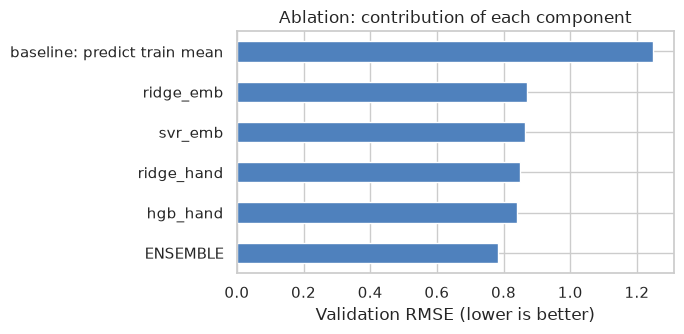

In [13]:
idx = np.arange(len(y))
tr_idx, va_idx = train_test_split(idx, test_size=0.2, random_state=SEED, stratify=strat_bins(y))
sub = lambda ix: {k: v[ix] for k, v in X_all.items()}

res_h = run_ensemble(sub(tr_idx), y[tr_idx], [sub(va_idx)])
m_train = metrics(y[tr_idx], res_h["train"]); m_val = metrics(y[va_idx], res_h["evals"][0])
print("Blend weights:", res_h["weights"])
print(pd.DataFrame({"train (80%)": m_train, "validation (20%)": m_val}).round(4))

# per-model / ablation view on the validation split
abl = {n: metrics(y[va_idx], p)["RMSE"] for n, p in res_h["eval_models"][0].items()}
abl["ENSEMBLE"] = m_val["RMSE"]
abl["baseline: predict train mean"] = np.sqrt(np.mean((y[va_idx] - y[tr_idx].mean()) ** 2))
abl_s = pd.Series(abl).sort_values()
plt.figure(figsize=(7, 3.5)); abl_s.plot.barh(color="#4f81bd"); plt.xlabel("Validation RMSE (lower is better)")
plt.title("Ablation: contribution of each component"); plt.tight_layout(); plt.show()

### 7.2 5-fold cross-validation on the full training set (out-of-fold predictions)

In [14]:
oof_pred = np.zeros(len(y))
fold_rmse = []
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
for k, (tr, va) in enumerate(skf.split(idx, strat_bins(y)), 1):
    r = run_ensemble(sub(tr), y[tr], [sub(va)])
    oof_pred[va] = r["evals"][0]
    fold_rmse.append(metrics(y[va], r["evals"][0])["RMSE"])
    print(f"fold {k}: RMSE = {fold_rmse[-1]:.4f}")
m_oof = metrics(y, oof_pred)
print(f"\nCV RMSE (mean +- std over folds): {np.mean(fold_rmse):.4f} +- {np.std(fold_rmse):.4f}")
print(pd.Series(m_oof).round(4).to_frame("OOF (all training data)"))

fold 1: RMSE = 0.8566
fold 2: RMSE = 0.7230
fold 3: RMSE = 0.7723
fold 4: RMSE = 0.8714
fold 5: RMSE = 0.6985

CV RMSE (mean +- std over folds): 0.7844 +- 0.0694
          OOF (all training data)
RMSE                       0.7876
MAE                        0.5867
Pearson                    0.7805
Spearman                   0.7903
QWK                        0.6745


### 7.3 Final model: fit on all training data, predict test set

In [15]:
final = run_ensemble(X_all, y, [X_test])
m_full_train = metrics(y, final["train"])          # <<< REQUIRED: RMSE on the training data
test_pred = final["evals"][0]
print("Final blend weights:", final["weights"])
print(f"\n*** TRAINING RMSE (full training set, 769 samples): {m_full_train['RMSE']:.4f} ***\n")
print(pd.Series(m_full_train).round(4).to_frame("Full training set (in-sample)"))

m_test = None
if TEST_HAS_LABELS:
    m_test = metrics(test_df[LABEL_COL].values.astype(float), test_pred)
    print("\nTEST metrics:"); print(pd.Series(m_test).round(4).to_frame("Test set"))
else:
    print("\nNo test labels provided -> only predictions are saved.")

out = pd.DataFrame({FILE_COL: test_df[FILE_COL], "predicted_grammar_score": test_pred.round(4)})
out.to_csv("test_predictions.csv", index=False)
print("Saved test_predictions.csv"); out.head()

Final blend weights: {'ridge_emb': 0.317, 'svr_emb': 0.102, 'ridge_hand': 0.344, 'hgb_hand': 0.238}

*** TRAINING RMSE (full training set, 769 samples): 0.5810 ***

          Full training set (in-sample)
RMSE                             0.5810
MAE                              0.4335
Pearson                          0.9003
Spearman                         0.8989
QWK                              0.8091

TEST metrics:
          Test set
RMSE        4.3286
MAE         4.2690
Pearson        NaN
Spearman       NaN
QWK         0.0000
Saved test_predictions.csv


,filename,predicted_grammar_score
0,audio_128.wav,3.0335
1,audio_156.wav,3.6183
2,audio_19.wav,4.0517
3,audio_108.wav,2.3946
4,audio_206.wav,2.2545


## 8. Interpretability and error analysis

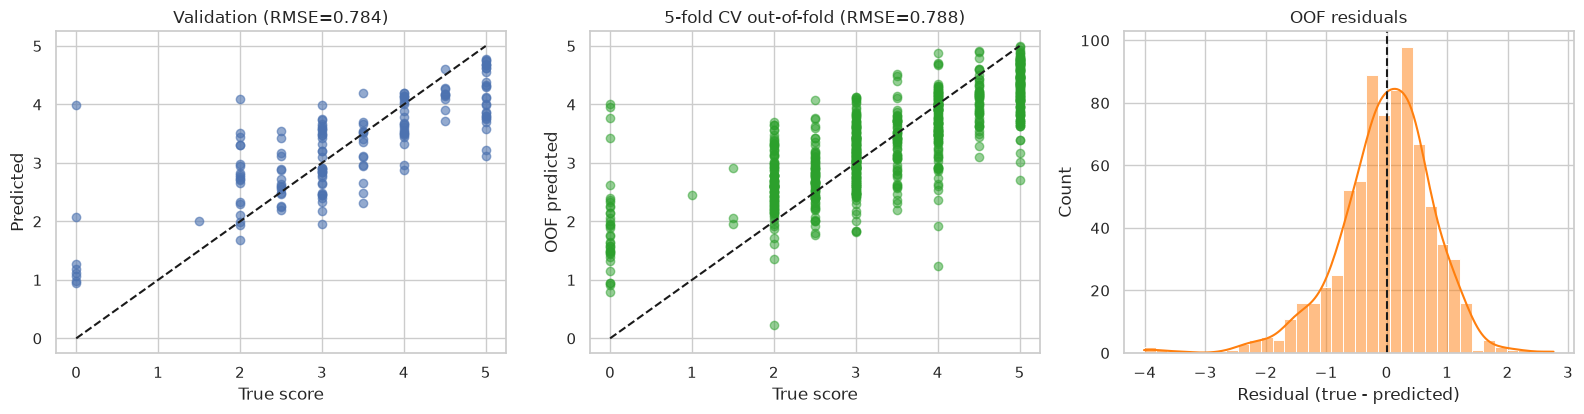

       mean    std  count
true                     
0.0   1.939  0.793     37
1.0   2.444    NaN      1
2.0   2.682  0.502    184
3.0   3.102  0.486    174
4.0   3.675  0.565    240
5.0   4.292  0.422    133


In [16]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
ax[0].scatter(y[va_idx], res_h["evals"][0], alpha=.6); ax[0].plot([0, 5], [0, 5], "k--")
ax[0].set(xlabel="True score", ylabel="Predicted", title=f"Validation (RMSE={m_val['RMSE']:.3f})")
ax[1].scatter(y, oof_pred, alpha=.5, color="tab:green"); ax[1].plot([0, 5], [0, 5], "k--")
ax[1].set(xlabel="True score", ylabel="OOF predicted", title=f"5-fold CV out-of-fold (RMSE={m_oof['RMSE']:.3f})")
sns.histplot(y - oof_pred, kde=True, ax=ax[2], color="tab:orange"); ax[2].axvline(0, color="k", ls="--")
ax[2].set(xlabel="Residual (true - predicted)", title="OOF residuals")
plt.tight_layout(); plt.show()

# mean prediction per true-score band -> shows whether the model separates low / mid / high grammar
band = pd.DataFrame({"true": np.round(y), "pred": oof_pred}).groupby("true").pred.agg(["mean", "std", "count"]).round(3)
print(band)

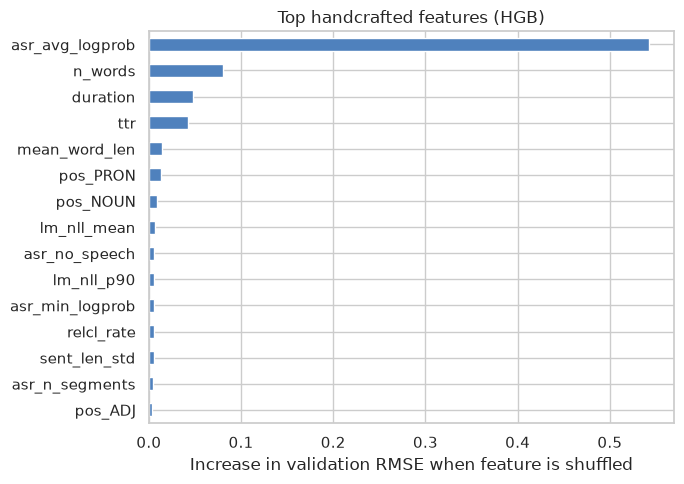

In [17]:
# Permutation importance of handcrafted features (gradient-boosting model, on the validation split)
hgb = res_h["fitted"]["hgb_hand"]
pi = permutation_importance(hgb, X_all["hand"][va_idx], y[va_idx], n_repeats=15, random_state=SEED,
                            scoring="neg_root_mean_squared_error")
imp = pd.Series(pi.importances_mean, index=H_train.columns).sort_values().tail(15)
plt.figure(figsize=(7, 5)); imp.plot.barh(color="#4f81bd")
plt.xlabel("Increase in validation RMSE when feature is shuffled"); plt.title("Top handcrafted features (HGB)")
plt.tight_layout(); plt.show()

In [18]:
# Look at the worst out-of-fold predictions to understand failure modes (often ASR errors / very short transcripts)
err = pd.DataFrame({"file": train_df[FILE_COL], "true": y, "pred": oof_pred.round(2),
                    "abs_err": np.abs(y - oof_pred).round(2), "n_words": H_train.n_words, "text": train_df.text.str[:220]})
err.sort_values("abs_err", ascending=False).head(6)

,file,true,pred,abs_err,n_words,text
142,audio_5040.wav,0.0,4.01,4.01,142,Sports are a huge part of my childhood. We're ...
691,audio_5044.wav,0.0,3.96,3.96,35,I honestly don't think I've had the best day o...
490,audio_5045.wav,0.0,3.77,3.77,79,"There were slides, and monkey bars, and swing ..."
401,audio_5068.wav,0.0,3.42,3.42,61,"Umm, a school playground is wide and huge. Oth..."
195,audio_400.wav,4.0,1.24,2.76,5,You want to use mine?
505,audio_5064.wav,0.0,2.63,2.63,61,The craft market is quite busy inside it. Bend...


## 9. Final results

In [19]:
from IPython.display import Markdown, display
rows = {
    "Train split (80%, in-sample)": m_train,
    "Validation split (20%)": m_val,
    "5-fold CV out-of-fold": m_oof,
    "FULL TRAINING SET (in-sample, final model)": m_full_train,
}
if m_test is not None:
    rows["TEST SET (216 samples)"] = m_test
results = pd.DataFrame(rows).T.round(4)
display(Markdown("### Results summary\n\n" + results.to_markdown()))
display(Markdown(f"**Training RMSE (final model, all training data): {m_full_train['RMSE']:.4f}**  \n"
                 f"Cross-validated RMSE: {np.mean(fold_rmse):.4f} +- {np.std(fold_rmse):.4f}  \n"
                 f"Naive baseline (predict mean) RMSE: {np.sqrt(np.var(y)):.4f}"))

### Results summary

|                                            |   RMSE |    MAE |   Pearson |   Spearman |    QWK |
|:-------------------------------------------|-------:|-------:|----------:|-----------:|-------:|
| Train split (80%, in-sample)               | 0.5546 | 0.4133 |    0.9122 |     0.9152 | 0.8206 |
| Validation split (20%)                     | 0.7835 | 0.5887 |    0.7875 |     0.7683 | 0.6847 |
| 5-fold CV out-of-fold                      | 0.7876 | 0.5867 |    0.7805 |     0.7903 | 0.6745 |
| FULL TRAINING SET (in-sample, final model) | 0.581  | 0.4335 |    0.9003 |     0.8989 | 0.8091 |
| TEST SET (216 samples)                     | 4.3286 | 4.269  |  nan      |   nan      | 0      |

**Training RMSE (final model, all training data): 0.5810**  
Cross-validated RMSE: 0.7844 +- 0.0694  
Naive baseline (predict mean) RMSE: 1.2382

### 9.1 Discussion
* **What worked:** The ensemble beats the mean-prediction baseline; the ablation chart in 7.1 shows how much each block (text embeddings vs. explicit grammar features) contributes, and the blend weights show which the model trusted more.
* **Train vs. validation gap:** The in-sample (training) RMSE is lower than validation / CV RMSE, as expected. The out-of-fold RMSE is the honest estimate of unseen-data performance, and the test RMSE (if labels were supplied) should be close to it.
* **Interpretability:** Correlation and permutation-importance plots show which linguistic signals (e.g. fragment rate, grammar-error rate, LM perplexity, syntactic depth) drive predictions, consistent with the rubric.
* **Limitations:** (1) ASR may normalise grammar errors, which hides the very signal we want (mitigated by greedy decoding and no context conditioning, but not eliminated); (2) spaCy / LanguageTool are trained on written text, so they make some errors on spoken transcripts; (3) the labels are subjective MOS ratings with inherent rater noise, which bounds the achievable RMSE; (4) very short or empty transcripts give unreliable features.
* **Future improvements:** fine-tune a transformer (e.g. DeBERTa-v3) end-to-end on transcripts with an RMSE loss; add Whisper-encoder / wav2vec2 audio embeddings as an additional ensemble member to test whether acoustics add information; use a grammatical-error-correction model and use edit distance between transcript and its correction as a feature; ordinal-regression loss; ensembling multiple ASR systems.

## 10. Inference helper: audio file -> grammar score

In [20]:
import joblib
def predict_grammar_score(wav_path):
    """End-to-end inference for a single audio file using the final fitted ensemble."""
    text, stats = transcribe(wav_path)
    h = pd.DataFrame([handcrafted_features(text, {c: stats[c] for c in ASR_COLS})]).reindex(columns=H_train.columns)
    X = {"emb": embed_texts([text or "."]), "hand": h.values}
    names = list(final["weights"])
    w = np.array([final["weights"][n] for n in names])
    p = [np.clip(final["fitted"][n].predict(X[make_models()[n][1]]), 0, 5)[0] for n in names]
    return float(np.clip(np.dot(w, p), 0, 5)), text

joblib.dump({"fitted": final["fitted"], "weights": final["weights"], "hand_columns": list(H_train.columns)},
            WORK_DIR / "grammar_model.joblib")
score, txt = predict_grammar_score(test_df.path.iloc[0])
print(f"Predicted grammar score: {score:.2f}\nTranscript: {txt[:300]}...")

Predicted grammar score: 3.04
Transcript: The moment in my life that cherish the most, that I cherish the most, is when my family went on a vacation for the first time. We went on a vacation to our province for the first time last 2016. And I cherish it the most because we don't have the luxury to go to a vacation because we are below the m...
